Cell 1: Import Thư viện & Thiết lập

In [1]:
# ==========================================
# CELL 1: KHAI BÁO THƯ VIỆN
# ==========================================
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

from stable_baselines3 import DQN
from stable_baselines3.common.env_checker import check_env

import warnings
warnings.filterwarnings('ignore') # Tắt các cảnh báo đỏ để notebook đẹp hơn

print("Thư viện đã được tải thành công cho Version 3!")

Thư viện đã được tải thành công cho Version 3!


Cell 2: Định nghĩa Môi trường RL (Data-Driven Bandwidth Env)

In [2]:
# ==========================================
# CELL 2: XÂY DỰNG MÔI TRƯỜNG GYMNASIUM (PURE DATA-DRIVEN)
# ==========================================
class BandwidthVideoRoutingEnv(gym.Env):
    """
    Môi trường mô phỏng mạng SDN dựa trên thông số Băng thông thực tế (Mbps).
    Không sử dụng thông số ảo (Delay/Loss) để đảm bảo tính thực tiễn khi deploy.
    """
    metadata = {"render_modes":["human"]}

    def __init__(self):
        super(BandwidthVideoRoutingEnv, self).__init__()
        self.max_steps = 200     # Độ dài 1 tập huấn luyện (Episode)
        self.current_step = 0
        self.num_links = 10      # Tổng số đường link trong đồ thị mạng 6 nút
        
        # Định nghĩa 4 đường đi (Paths) từ Node U đến Node Z
        self.paths = {
            0: [1, 8],       # Path 0: u -> w -> z (Đường dự phòng trên)
            1: [2, 6, 9],    # Path 1: u -> x -> y -> z (Đường ngắn nhất mặc định)
            2:[0, 3, 8],    # Path 2: u -> v -> w -> z (Đường vòng)
            3:[2, 5, 8]     # Path 3: u -> x -> w -> z (Đường dự phòng dưới)
        }
        
        # Action Space: 4 lựa chọn tương ứng với 4 Paths
        self.action_space = spaces.Discrete(4)
        
        # Observation Space: Mảng 10 phần tử đại diện cho Băng thông (0 -> 10 Mbps) của 10 links
        self.observation_space = spaces.Box(
            low=0.0, high=10.0, shape=(self.num_links,), dtype=np.float32
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        # Khởi tạo trạng thái mạng rảnh rỗi (Băng thông nền từ 0.5 đến 1.5 Mbps)
        self.state = np.random.uniform(0.5, 1.5, self.num_links).astype(np.float32)
        return self.state, {}

    def step(self, action):
        self.current_step += 1
        
        # Reset trạng thái các link về bình thường ở mỗi bước
        self.state = np.random.uniform(0.5, 1.5, self.num_links).astype(np.float32)

        # MÔ PHỎNG TẮC NGHẼN: Từ bước 50 đến 150, Link số 9 (thuộc Path 1) bị Iperf làm nghẽn
        if 50 <= self.current_step <= 150:
            self.state[9] = np.random.uniform(8.5, 9.8) # Băng thông vọt lên sát mức tới hạn 10Mbps
            
        # Lấy danh sách các link thuộc đường đi mà Agent vừa chọn
        chosen_path_links = self.paths[action]
        
        # Tìm mức băng thông cao nhất (chỗ nghẽn nhất) trên con đường đó
        max_bandwidth_on_path = max([self.state[i] for i in chosen_path_links])
        
        # TÍNH PHẦN THƯỞNG (REWARD FUNCTION)
        # Băng thông càng cao (càng kẹt) -> Điểm càng thấp
        # Băng thông càng thấp (đường thoáng) -> Điểm càng cao
        reward = 10.0 - max_bandwidth_on_path
        
        terminated = False
        truncated = self.current_step >= self.max_steps
        
        return self.state, float(reward), terminated, truncated, {}

# Kiểm tra tính hợp lệ của môi trường
env = BandwidthVideoRoutingEnv()
check_env(env)
print("Môi trường Mạng (Bandwidth-based) đã sẵn sàng!")

Môi trường Mạng (Bandwidth-based) đã sẵn sàng!


Cell 3: Huấn luyện và Lưu Mô hình


In [3]:
# ==========================================
# CELL 3: KHỞI TẠO VÀ HUẤN LUYỆN RL AGENT (DQN)
# ==========================================
print("Bắt đầu quá trình huấn luyện mạng Nơ-ron (Deep Q-Network)...")

# Khởi tạo thuật toán DQN với Policy Mạng nơ-ron truyền thẳng (MlpPolicy)
model = DQN(
    "MlpPolicy", 
    env, 
    learning_rate=1e-3, 
    buffer_size=50000, 
    exploration_fraction=0.1, # Dành 10% thời gian đầu để khám phá ngẫu nhiên
    verbose=0
)

# Tiến hành huấn luyện qua 20,000 bước
model.learn(total_timesteps=20000)

# LƯU MÔ HÌNH: Dùng tên v3 để phân biệt với các bản trước
model.save("dqn_model_v3")

print("Huấn luyện thành công! Đã lưu file 'dqn_model_v3.zip'.")

Bắt đầu quá trình huấn luyện mạng Nơ-ron (Deep Q-Network)...
Huấn luyện thành công! Đã lưu file 'dqn_model_v3.zip'.


Cell 4: Đánh giá & Vẽ Biểu đồ (Phần Quan trọng cho Báo cáo)

Đang tiến hành mô phỏng so sánh giữa RL Agent, Greedy (STP/OSPF), và Random...


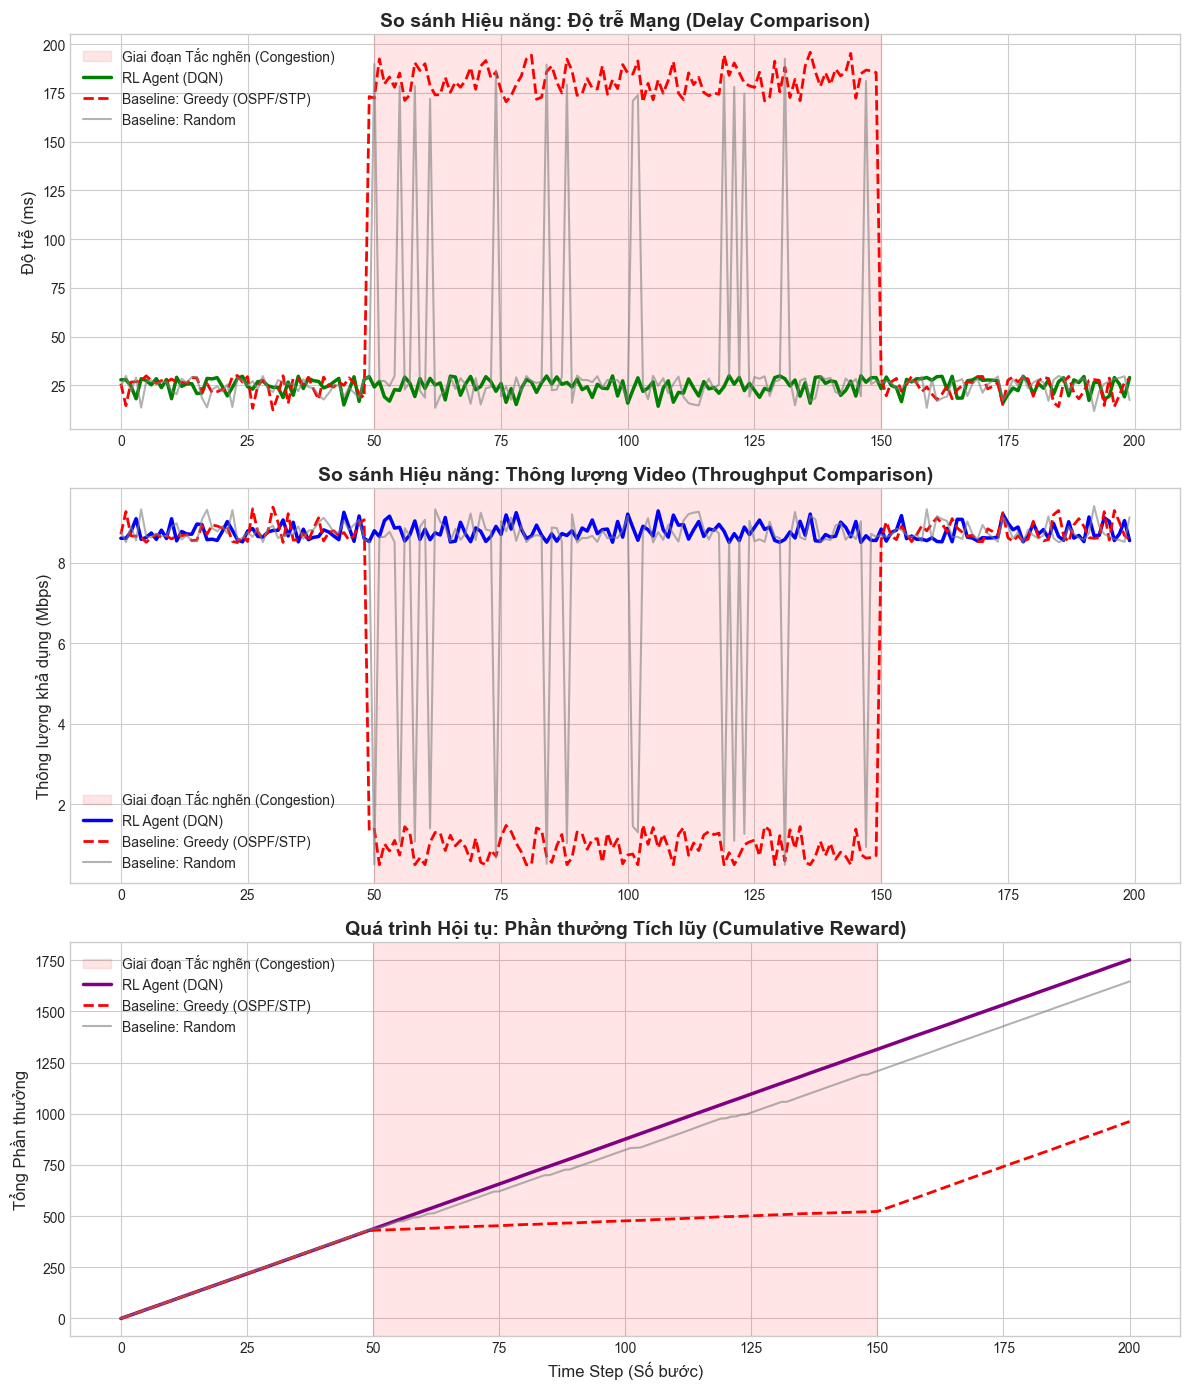

Đã lưu biểu đồ thành công! File: evaluation_metrics_v3.png


In [4]:
# ==========================================
# CELL 4: SO SÁNH HIỆU NĂNG VÀ TRỰC QUAN HÓA KẾT QUẢ (VISUALIZATION)
# ==========================================
print("Đang tiến hành mô phỏng so sánh giữa RL Agent, Greedy (STP/OSPF), và Random...")

# Load lại mô hình vừa train
model = DQN.load("dqn_model_v3")

# Định nghĩa các thuật toán đối thủ (Baselines)
def greedy_policy():
    return 1  # Luôn chọn Path 1 (Đường ngắn nhất) bất chấp kẹt xe

def random_policy():
    return np.random.randint(0, 4) # Chọn bừa đường đi

# Khởi tạo các mảng lưu số liệu để vẽ biểu đồ
steps = 200
metrics = {
    "RL": {"delay": [], "throughput": [], "cumulative_reward":[0]},
    "Greedy": {"delay":[], "throughput":[], "cumulative_reward": [0]},
    "Random": {"delay": [], "throughput":[], "cumulative_reward": [0]}
}

# Vòng lặp đánh giá
for policy_name in["RL", "Greedy", "Random"]:
    obs, _ = env.reset()
    cum_reward = 0
    
    for step in range(steps):
        # Phân loại thuật toán
        if policy_name == "RL":
            action, _ = model.predict(obs, deterministic=True)
            action = int(action)
        elif policy_name == "Greedy":
            action = greedy_policy()
        else:
            action = random_policy()
            
        # Thực thi vào môi trường
        obs, reward, _, _, _ = env.step(action)
        
        # Phục hồi các chỉ số giả lập (Dựa vào Reward) để vẽ biểu đồ cho dễ hiểu
        chosen_bw = 10.0 - reward 
        simulated_delay = chosen_bw * 20.0  # Băng thông kẹt -> Trễ cao
        simulated_throughput = max(0.5, 10.0 - chosen_bw) # Băng thông dư cho Video
        cum_reward += reward
        
        # Lưu dữ liệu
        metrics[policy_name]["cumulative_reward"].append(cum_reward)
        metrics[policy_name]["delay"].append(simulated_delay)
        metrics[policy_name]["throughput"].append(simulated_throughput)

# --- VẼ BIỂU ĐỒ BẰNG MATPLOTLIB ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

# Tô màu vùng xảy ra tắc nghẽn
for ax in axs:
    ax.axvspan(50, 150, color='red', alpha=0.1, label='Giai đoạn Tắc nghẽn (Congestion)')

# 1. Biểu đồ Độ trễ
axs[0].plot(metrics["RL"]["delay"], label="RL Agent (DQN)", color='green', linewidth=2.5)
axs[0].plot(metrics["Greedy"]["delay"], label="Baseline: Greedy (OSPF/STP)", color='red', linestyle='--', linewidth=2)
axs[0].plot(metrics["Random"]["delay"], label="Baseline: Random", color='gray', alpha=0.6)
axs[0].set_title("So sánh Hiệu năng: Độ trễ Mạng (Delay Comparison)", fontsize=14, fontweight='bold')
axs[0].set_ylabel("Độ trễ (ms)", fontsize=12)
axs[0].legend(loc='upper left')

# 2. Biểu đồ Thông lượng
axs[1].plot(metrics["RL"]["throughput"], label="RL Agent (DQN)", color='blue', linewidth=2.5)
axs[1].plot(metrics["Greedy"]["throughput"], label="Baseline: Greedy (OSPF/STP)", color='red', linestyle='--', linewidth=2)
axs[1].plot(metrics["Random"]["throughput"], label="Baseline: Random", color='gray', alpha=0.6)
axs[1].set_title("So sánh Hiệu năng: Thông lượng Video (Throughput Comparison)", fontsize=14, fontweight='bold')
axs[1].set_ylabel("Thông lượng khả dụng (Mbps)", fontsize=12)
axs[1].legend(loc='lower left')

# 3. Biểu đồ Phần thưởng tích lũy
axs[2].plot(metrics["RL"]["cumulative_reward"], label="RL Agent (DQN)", color='purple', linewidth=2.5)
axs[2].plot(metrics["Greedy"]["cumulative_reward"], label="Baseline: Greedy (OSPF/STP)", color='red', linestyle='--', linewidth=2)
axs[2].plot(metrics["Random"]["cumulative_reward"], label="Baseline: Random", color='gray', alpha=0.6)
axs[2].set_title("Quá trình Hội tụ: Phần thưởng Tích lũy (Cumulative Reward)", fontsize=14, fontweight='bold')
axs[2].set_xlabel("Time Step (Số bước)", fontsize=12)
axs[2].set_ylabel("Tổng Phần thưởng", fontsize=12)
axs[2].legend(loc='upper left')

plt.tight_layout()
plt.show()

# Xuất ảnh chất lượng cao để chèn vào Word
fig.savefig("evaluation_metrics_v3.png", dpi=300)
print("Đã lưu biểu đồ thành công! File: evaluation_metrics_v3.png")